<a href="https://colab.research.google.com/github/SanaFathimaKS/ML-LAB1/blob/main/exp3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score

In [4]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
column_names = ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin', 'car_name']

data = pd.read_csv(url, names=column_names, sep=r'\s+', na_values='?')
data.dropna(inplace=True)
data["displacement"] = data["displacement"].astype(float)

In [5]:
X = data[["displacement"]]
y = data["mpg"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [6]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred_linear = linear_model.predict(X_test)
linear_mse = mean_squared_error(y_test, y_pred_linear)
linear_r2 = r2_score(y_test, y_pred_linear)

In [7]:
poly2 = PolynomialFeatures(degree=2)
X_train_poly2 = poly2.fit_transform(X_train)
X_test_poly2 = poly2.transform(X_test)
poly_model2 = LinearRegression()
poly_model2.fit(X_train_poly2, y_train)
y_pred_poly2 = poly_model2.predict(X_test_poly2)
poly2_mse = mean_squared_error(y_test, y_pred_poly2)
poly2_r2 = r2_score(y_test, y_pred_poly2)

In [8]:
poly3 = PolynomialFeatures(degree=3)
X_train_poly3 = poly3.fit_transform(X_train)
X_test_poly3 = poly3.transform(X_test)
poly_model3 = LinearRegression()
poly_model3.fit(X_train_poly3, y_train)
y_pred_poly3 = poly_model3.predict(X_test_poly3)
poly3_mse = mean_squared_error(y_test, y_pred_poly3)
poly3_r2 = r2_score(y_test, y_pred_poly3)

In [9]:
poly3 = PolynomialFeatures(degree=3)
X_train_poly3 = poly3.fit_transform(X_train)
X_test_poly3 = poly3.transform(X_test)
poly_model3 = LinearRegression()
poly_model3.fit(X_train_poly3, y_train)
y_pred_poly3 = poly_model3.predict(X_test_poly3)
poly3_mse = mean_squared_error(y_test, y_pred_poly3)
poly3_r2 = r2_score(y_test, y_pred_poly3)

In [11]:
comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Polynomial (Degree 2)', 'Polynomial (Degree 3)'],
    'MSE': [linear_mse, poly2_mse, poly3_mse],
    'R2': [linear_r2, poly2_r2, poly3_r2]
})
print(comparison)

                   Model        MSE        R2
0      Linear Regression  21.227484  0.584106
1  Polynomial (Degree 2)  20.649055  0.595439
2  Polynomial (Degree 3)  20.817941  0.592130


In [12]:
X_plot = pd.DataFrame(
    np.linspace(X["displacement"].min(), X["displacement"].max(),300),
    columns=["displacement"]
)


In [13]:
X_plot_poly = poly2.transform(X_plot)
y_plot = poly_model2.predict(X_plot_poly)


Text(0, 0.5, 'Miles Per Gallon (MPG)')

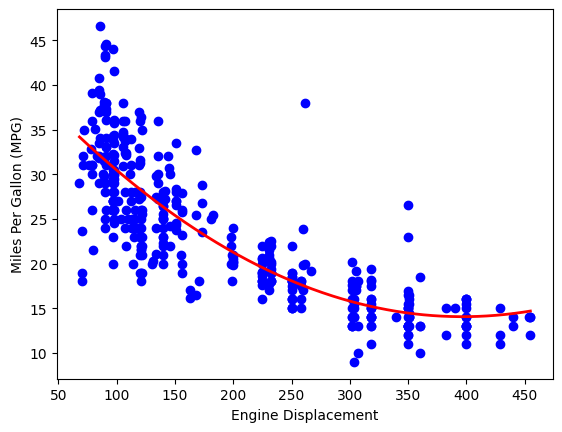

In [14]:
plt.scatter(X, y, color="blue", label="Actual Data")
plt.plot(X_plot["displacement"], y_plot, color="red", linewidth=2,
         label="Polynomial Regression (Degree 2)")
plt.xlabel("Engine Displacement")
plt.ylabel("Miles Per Gallon (MPG)")

Text(0, 0.5, 'Miles Per Gallon (MPG)')

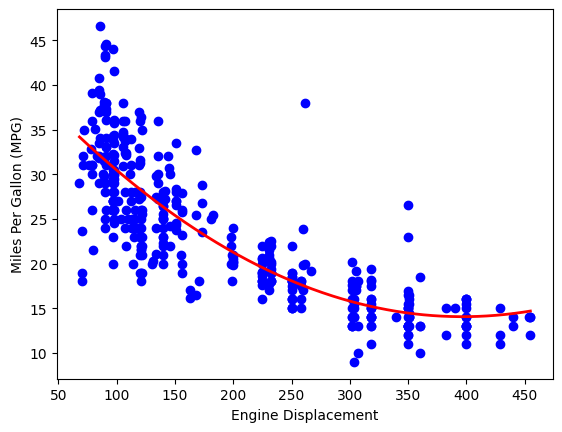

In [15]:
plt.scatter(X, y, color="blue", label="Actual Data")
plt.plot(X_plot["displacement"], y_plot, color="red", linewidth=2,
         label="Polynomial Regression (Degree 2)")
plt.xlabel("Engine Displacement")
plt.ylabel("Miles Per Gallon (MPG)")
